# Supplementary figures S8 (extreme events) and S9 (term contributions, response surfaces)

S8 (extreme-event hit rate) and S9 (term contributions + response surfaces).
S8: event = exceeds the observed 95th (and 90th) percentile; scored on leave-one-year-out
predictions of (i) the neural-net pipeline in both cities and (ii) Bogota's lead equations
and persistence. S9: per-term contribution and response surface of the lead equations.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, sympy as sp
import matplotlib.pyplot as plt
from termmap_utils import DATA, equation_variables
from common.feature_selection import loyo_predictions, nn_in_sample_model
from common.diagnostics import pysr_term_contributions, response_surface_comparison
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label
from fig_common import VAR_LABELS   # readable axis labels (2026-09-23), not raw code identifiers

In [2]:
# Settings (edit here, then Run All)
FIGSIZE = dict(S08=(11, 4.2), S09_pm25_bars=(6.4, 3.4))
EVENT_PCT = 95                           # percentile defining an event in the S8 bars
PM25 = PM25_BLUE                         # blue instead of orange in every SI figure (2026-09-23, user request)

    city pollutant                      model  pct    n  hit_rate   far   csi  n_events
  Bogota      pm25 neural-net pipeline (LOYO)   90 3283     0.480 0.288 0.402       329
  Bogota      pm25 neural-net pipeline (LOYO)   95 3283     0.327 0.407 0.267       165
  Bogota        o3 neural-net pipeline (LOYO)   90 2917     0.432 0.296 0.365       292
  Bogota        o3 neural-net pipeline (LOYO)   95 2917     0.301 0.397 0.251       146
Medellin      pm25 neural-net pipeline (LOYO)   90 2012     0.450 0.283 0.382       202
Medellin      pm25 neural-net pipeline (LOYO)   95 2012     0.416 0.288 0.356       101
Medellin        o3 neural-net pipeline (LOYO)   90 1389     0.230 0.360 0.204       139
Medellin        o3 neural-net pipeline (LOYO)   95 1389     0.157 0.312 0.147        70
  Bogota      pm25       lead equation (LOYO)   90 3283     0.398 0.284 0.344       329
  Bogota      pm25       lead equation (LOYO)   95 3283     0.267 0.429 0.222       165
  Bogota      pm25    persistenc

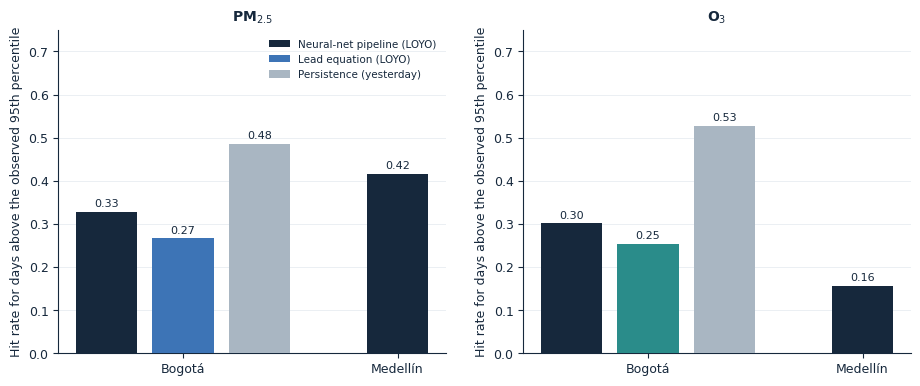

In [3]:
# Analysis
B, M = DATA / "bogota", DATA / "medellin"
def rd(p):
    d = pd.read_parquet(p); d["date"] = pd.to_datetime(d["date"]); d["year"] = d["date"].dt.year; return d

def event_scores(y, p, q):
    thr = np.percentile(y, q); o = y >= thr; e = p >= thr
    tp, fn, fp = int((o & e).sum()), int((o & ~e).sum()), int((~o & e).sum())
    return dict(hit_rate=tp / (tp + fn), far=fp / (tp + fp) if tp + fp else np.nan, csi=tp / (tp + fn + fp), n_events=tp + fn)

rows = []
cfg = [("Bogota", "pm25", B/"bogota_master_dataset.parquet", B/"bogota_feature_selection.json"),
       ("Bogota", "o3", B/"bogota_o3_master_dataset.parquet", B/"bogota_o3_feature_selection.json"),
       ("Medellin", "pm25", M/"medellin_master_dataset.parquet", M/"medellin_feature_selection.json"),
       ("Medellin", "o3", M/"medellin_o3_master_dataset.parquet", M/"medellin_o3_feature_selection.json")]
for city, pol, mp, sp_ in cfg:
    d = rd(mp); feats = json.load(open(sp_))["selected_no_lag"]
    y, p = loyo_predictions(d, feats, pol)
    for q in (90, 95):
        rows.append(dict(city=city, pollutant=pol, model="neural-net pipeline (LOYO)", pct=q, n=len(y), **event_scores(y, p, q)))
for pol in ("pm25", "o3"):
    pr = pd.read_csv(DATA_OUT / f"loyo_predictions_{pol}.csv")
    for q in (90, 95): rows.append(dict(city="Bogota", pollutant=pol, model="lead equation (LOYO)", pct=q, n=len(pr), **event_scores(pr.obs.to_numpy(), pr.pred_loyo.to_numpy(), q)))
    d = rd(B / ("bogota_master_dataset.parquet" if pol == "pm25" else "bogota_o3_master_dataset.parquet"))
    d = d.merge(pr[["date"]].assign(date=pd.to_datetime(pr["date"])), on="date").dropna(subset=[pol, f"{pol}_lag1"])   # identical rows to the equation
    for q in (90, 95): rows.append(dict(city="Bogota", pollutant=pol, model="persistence (yesterday)", pct=q, n=len(d), **event_scores(d[pol].to_numpy(), d[f"{pol}_lag1"].to_numpy(), q)))
t = pd.DataFrame(rows); t.to_csv(DATA_OUT / "extreme_event_scores.csv", index=False)
print(t.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE['S08'], gridspec_kw=dict(wspace=0.2))
models = ["neural-net pipeline (LOYO)", "lead equation (LOYO)", "persistence (yesterday)"]
for ax, pol, ttl in zip(axes, ["pm25", "o3"], ["PM$_{2.5}$", "O$_3$"]):
    x0 = 0
    for city in ["Bogota", "Medellin"]:
        for m, col in zip(models, [NAVY, PM25 if pol == "pm25" else O3, GREY]):
            s = t[(t.city == city) & (t.pollutant == pol) & (t.model == m) & (t.pct == EVENT_PCT)]
            if len(s):
                ax.bar(x0, s.hit_rate.iloc[0], color=col, width=0.8, label=m if city == "Bogota" else None, zorder=3)
                ax.text(x0, s.hit_rate.iloc[0] + 0.012, f"{s.hit_rate.iloc[0]:.2f}", ha="center", fontsize=8)
            x0 += 1
        x0 += 0.8
    ax.set_xticks([1, 3.8]); ax.set_xticklabels(["Bogotá", "Medellín"]); ax.set_ylim(0, 0.75)
    ax.set_title(ttl); ax.set_ylabel(f"hit rate for days above the observed {EVENT_PCT}th percentile"); ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
axes[0].legend(frameon=False, fontsize=7.5, loc="upper right")
save_fig(fig, "figS08_extreme_events")

                                           component  share_of_log_variance
0                                     CO (emissions)               0.404938
1  ventilation term\n(1/$\sqrt{\mathrm{wind\ spee...               0.214561
2       fire term\n(north sector, east sector lag 2)               0.380501 | additive shares: CO term 0.619 fire term 0.381
                         component  share_of_log_variance
0        sunlight (SW$\downarrow$)               0.287366
1                           NO$_2$               0.211702
2                   NO (titration)               0.122237
3                       PM$_{2.5}$               0.245692
4  fire term\n(east sector, lag 2)               0.133299 | photochemical term 0.867 fire term 0.133
saved /path/to/project/Paper/figures/figS09a_term_contributions.png
saved /path/to/project/Paper/figures/figS09b_response_surfaces.png


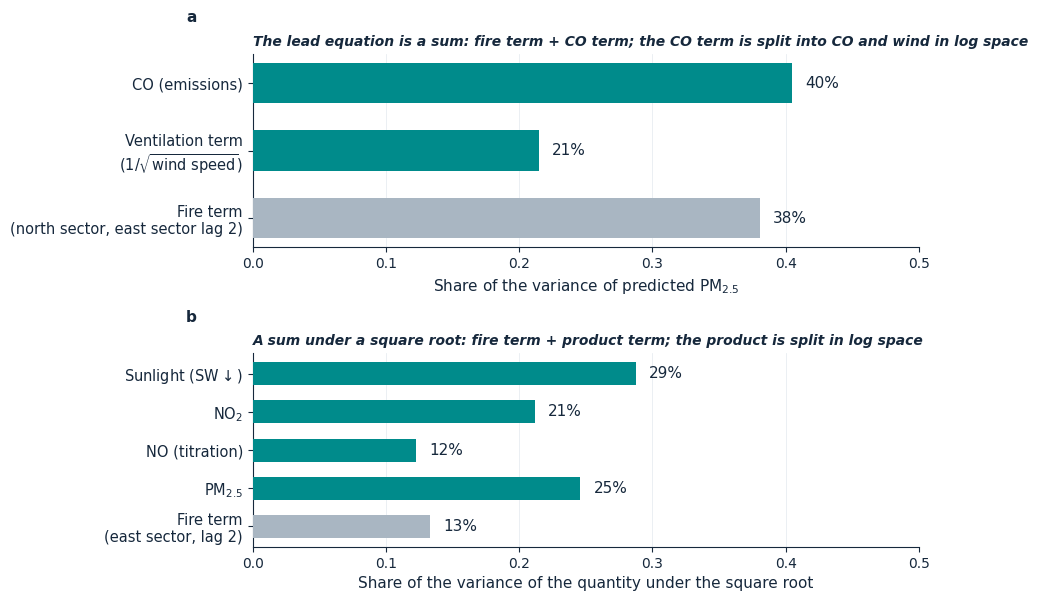

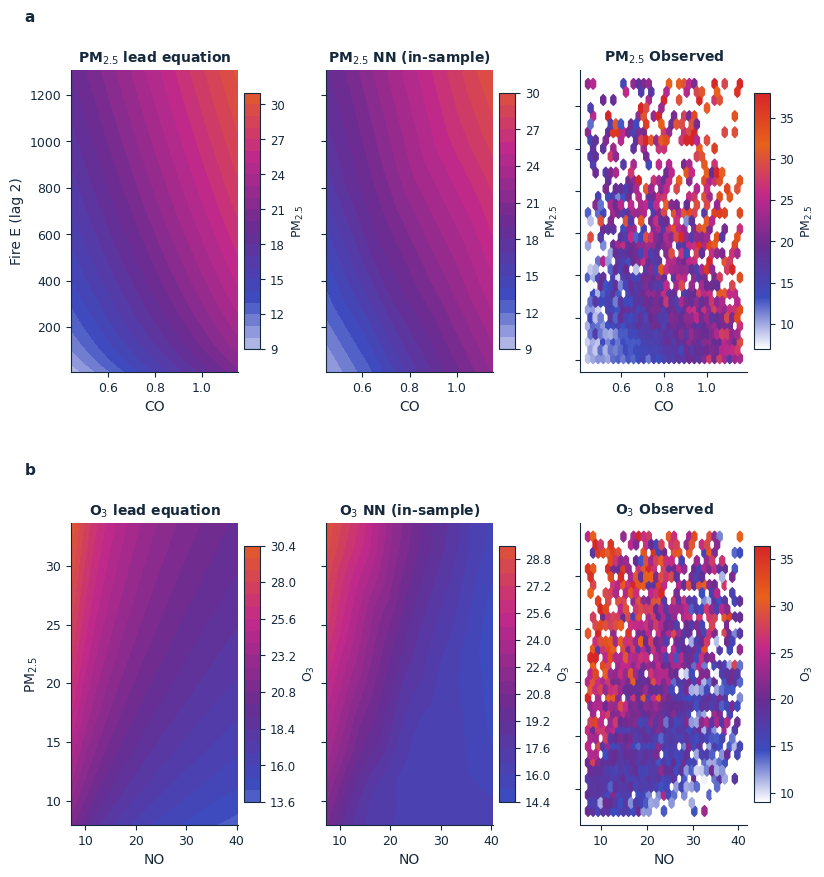

In [4]:
# S9
# 2026-09-24: was 4 separate PDFs (2 term-contribution bar charts, 2 3-panel response-surface
# figures) stitched into one 2x2 grid via 4 side-by-side \includegraphics calls in the manuscript at
# quarter-page size each -- illegible. First combined into a single 4-row figure, but panel (a) (only
# 3 bars) still looked half-empty stretched across a row sized to match the denser response-surface
# rows below it. Split into two properly-sized figures instead: figS09a (2 rows, one bar chart each)
# and figS09b (2 rows x 3 cols, the two response-surface triptychs). Bars changed from
# PM25_BLUE/default-blue to darkcyan per user request; the grey (weakest term) bar is unchanged.
BAR_COLOUR = "darkcyan"
# 2026-10-06: O3 lead = constrained front with T in the pool, complexity 15 (was the free-form c16); 2026-10-20: PM2.5 lead = c13 of the corrected-fire front
specs = [("pm25", B/"bogota_pm25_pysr_units_pareto_front.csv", 13, B/"bogota_master_dataset.parquet"),
         ("o3", B/"bogota_o3_pysr_units_fire2_pm_pareto_front_seed0.csv", 15, B/"bogota_o3_master_dataset.parquet")]
O3_SAMPLE = ["temp_2m", "no", "pm25", "w700", "photochemical_potential", "rh_2m"]   # same 2919 days as A2
RS_AXES = {"pm25": (None, None), "o3": ("no", "pm25")}   # response-surface axes; None = the function's default

figS9a, bar_axes = plt.subplots(2, 1, figsize=(8.6, 6.4), gridspec_kw=dict(hspace=0.55))
row_letters = iter("ab")
rs_data = {}   # pol -> (feats, d, f, scaler, nn) for the response-surface figure below

for pol, fp, c, mp in specs:
    front = pd.read_csv(fp); eq = front.loc[front.complexity == c, "equation"].iloc[0]
    feats = sorted(equation_variables(eq))
    d = rd(mp).dropna(subset=feats + (O3_SAMPLE if pol == "o3" else []) + [pol]).reset_index(drop=True)
    y = d[pol].to_numpy(float)
    bar_ax = bar_axes[0 if pol == "pm25" else 1]
    if pol == "pm25":
        # 2026-10-20: after the fire-file correction the PM2.5 lead is a SUM of two terms,
        #   PM2.5 = sqrt(a (fire_E_lag2 + fire_N)) + b CO / sqrt(u)
        # so the split is additive for the two terms (share = cov(term, prediction) / var(prediction)); the CO term is itself a
        # product, which is split into CO and wind speed in log space (shares of ln(CO / sqrt(u))), then scaled by its additive share.
        a_, b_ = 0.10428376, 15.679531
        Ff = np.sqrt(a_ * (d["hotspots_sector_E_lag2"] + d["hotspots_sector_N"]).clip(lower=0)); Cf = b_ * d["co"] / np.sqrt(d["wind_speed_era5"])
        pred_ = Ff + Cf
        share_F = float(np.cov(Ff, pred_)[0, 1] / np.var(pred_)); share_C = 1 - share_F
        lC = np.log(Cf); share_co_in = float(np.cov(np.log(d["co"]), lC)[0, 1] / np.var(lC)); share_u_in = 1 - share_co_in
        dec = pd.DataFrame(dict(component=["CO (emissions)", "ventilation term\n(1/$\\sqrt{\\mathrm{wind\\ speed}}$)", "fire term\n(north sector, east sector lag 2)"],
                                share_of_log_variance=[share_C * share_co_in, share_C * share_u_in, share_F]))
        dec.to_csv(DATA_OUT / "term_contributions_pm25.csv", index=False); print(dec, "| additive shares: CO term", round(share_C, 3), "fire term", round(share_F, 3))
        bar_ax.barh(range(3)[::-1], dec.share_of_log_variance, color=[BAR_COLOUR, BAR_COLOUR, GREY], height=0.6, zorder=3)
        for i, v_ in zip(range(3)[::-1], dec.share_of_log_variance): bar_ax.text(v_ + 0.01, i, f"{v_*100:.0f}%", va="center", fontsize=11)
        bar_ax.set_yticks(range(3)[::-1]); bar_ax.set_yticklabels(dec.component, fontsize=10.5); bar_ax.set_xlim(0, 0.5)
        bar_ax.set_xlabel("share of the variance of predicted PM$_{2.5}$", fontsize=11); bar_ax.grid(axis="x", color=LIGHT, lw=0.6, zorder=0)
        bar_ax.set_title("the lead equation is a sum: fire term + CO term; the CO term is split into CO and wind in log space", fontsize=10, style="italic", loc="left")
        bar_ax.tick_params(axis="x", labelsize=10)
    else:
        # 2026-10-20: O3 = sqrt( a SW sqrt(PM2.5 NO2 / NO) + b F_E,-2 ): a sum of a photochemical (product) term and an additive fire term inside the square root.
        # Share of the variance of the radicand carried by each term (cov(term, radicand) / var(radicand)); the photochemical term is a product and is split
        # in log space (ln SW + 1/2 ln PM2.5 + 1/2 ln NO2 - 1/2 ln NO), each share scaled by the photochemical term's share. Constants as printed by PySR.
        a_, b_ = 1 / 2.034343, 0.10787038
        Pt = a_ * d["radiation_mean"] * np.sqrt(d["pm25"] * d["no2"] / d["no"]); Ft = b_ * d["hotspots_sector_E_lag2"]; Rr = Pt + Ft
        sh_F = float(np.cov(Ft, Rr)[0, 1] / np.var(Rr)); sh_P = 1 - sh_F
        lpt = np.log(Pt); vpt = np.var(lpt)
        parts = [("sunlight (SW$\\downarrow$)", np.log(d["radiation_mean"])), ("NO$_2$", 0.5 * np.log(d["no2"])), ("NO (titration)", -0.5 * np.log(d["no"])), ("PM$_{2.5}$", 0.5 * np.log(d["pm25"]))]
        vals_ = [sh_P * float(np.cov(c_, lpt)[0, 1] / vpt) for _, c_ in parts] + [sh_F]
        dec = pd.DataFrame(dict(component=[c for c, _ in parts] + ["fire term\n(east sector, lag 2)"], share_of_log_variance=vals_))
        dec.to_csv(DATA_OUT / "term_contributions_o3.csv", index=False); print(dec, "| photochemical term", round(sh_P, 3), "fire term", round(sh_F, 3))
        n = len(dec)
        bar_ax.barh(range(n)[::-1], dec.share_of_log_variance, color=[BAR_COLOUR] * (n - 1) + [GREY], height=0.6, zorder=3)
        for i, v_ in zip(range(n)[::-1], dec.share_of_log_variance): bar_ax.text(v_ + 0.01, i, f"{v_*100:.0f}%", va="center", fontsize=11)
        bar_ax.set_yticks(range(n)[::-1]); bar_ax.set_yticklabels(dec.component, fontsize=10.5); bar_ax.set_xlim(0, 0.5)
        bar_ax.set_xlabel("share of the variance of the quantity under the square root", fontsize=11); bar_ax.grid(axis="x", color=LIGHT, lw=0.6, zorder=0)
        bar_ax.set_title("a sum under a square root: fire term + product term; the product is split in log space", fontsize=10, style="italic", loc="left")
        bar_ax.tick_params(axis="x", labelsize=10)
    panel_label(bar_ax, next(row_letters), x=-0.1, y=1.15)
    ns = {v: sp.Symbol(v) for v in feats}
    f = sp.lambdify([ns[v] for v in feats], sp.sympify(eq, locals={**ns, "sqrt": sp.sqrt, "log": sp.log, "exp": sp.exp}), "numpy")
    scaler, nn, _, _ = nn_in_sample_model(d, feats, pol)
    rs_data[pol] = (feats, d, f, scaler, nn)
save_fig(figS9a, "figS09a_term_contributions")

# 2026-09-24: this figure already renders at the same full page width as every other SI figure --
# the "blank space" the user saw was the page's fixed top/bottom margins looking large next to a
# comparatively SHORT figure (aspect ratio ~0.7). Made it taller so it fills more of the page once
# scaled to that same width, rather than changing width/height caps that weren't the binding constraint.
figS9b = plt.figure(figsize=(9.2, 9.8))
gsS9b = figS9b.add_gridspec(2, 3, hspace=0.5, wspace=0.25)
row_letters = iter("ab")
for pol, row in [("pm25", 0), ("o3", 1)]:
    feats, d, f, scaler, nn = rs_data[pol]
    target_label = VAR_LABELS[pol]   # VAR_LABELS already has "pm25" -> PM$_{2.5}$ and "o3" -> O$_3$
    rs_axes = [figS9b.add_subplot(gsS9b[row, i]) for i in range(3)]
    axes_before = set(figS9b.axes)
    fx, fy = RS_AXES[pol]
    response_surface_comparison(d, feats, pol, {"Lead eq.": lambda X: f(*[X[:, i] for i in range(X.shape[1])]),
                                                "NN (in-sample)": lambda X: nn.predict(scaler.transform(X))},
                                feature_x=fx, feature_y=fy,
                                label_map=VAR_LABELS, axes=rs_axes)   # readable axis/colorbar labels instead of raw code identifiers (2026-09-23)
    for ax in rs_axes:
        ax.set_title(f"{target_label} {ax.get_title().replace(' (predicted)', '')}", fontsize=10)
        ax.xaxis.label.set_fontsize(10); ax.yaxis.label.set_fontsize(10)
        ax.tick_params(labelsize=9)
    for cax in set(figS9b.axes) - axes_before:   # the colorbar axes the call just appended
        cax.tick_params(labelsize=8.5); cax.yaxis.label.set_fontsize(9)
    panel_label(rs_axes[0], next(row_letters), x=-0.28, y=1.15)

save_fig(figS9b, "figS09b_response_surfaces")